# Last-Mile Delivery Hub Location (Mixed-Integer Optimization)

**Business question:** A same-day grocery delivery company ("FreshFast") serves five city zones and can operate up to three micro-hubs. Each hub has a daily fixed cost and a capacity. **Which hubs should it open, and which zones should each hub serve, to meet all demand at the lowest total daily cost?**

**Approach:** a facility-location model (mixed-integer linear program) solved with Python and Gurobi.
- Binary decision: open or close each hub.
- Continuous decision: orders per day sent from each zone to each hub.
- Objective: minimize fixed hub cost + transport cost ($2 per km per order).
- Constraints: meet every zone's demand, respect hub capacity, and only route orders to open hubs.

I then compare three policies (at most two hubs, optimizer decides freely, all three hubs forced open) and test how sensitive the answer is to transport cost.

In [1]:
import gurobipy as gp
from gurobipy import GRB, quicksum
import pandas as pd
import matplotlib.pyplot as plt

# Quiet Gurobi environment (no licence banner or solver log in the output)
env = gp.Env(empty=True)
env.setParam("OutputFlag", 0)
_ = env.start()

## 1. Data

In [2]:
zones = ["Downtown", "University", "Suburbs", "Industrial", "Waterfront"]
hubs  = ["North", "Central", "South"]

demand   = {"Downtown": 20, "University": 15, "Suburbs": 25, "Industrial": 10, "Waterfront": 15}  # orders/day
capacity = {"North": 50, "Central": 40, "South": 60}                                              # orders/day
fixed    = {"North": 2500, "Central": 2000, "South": 3000}                                         # $/day

dist = {  # km from zone to hub
    ("Downtown", "North"): 4,   ("Downtown", "Central"): 6,   ("Downtown", "South"): 9,
    ("University", "North"): 5, ("University", "Central"): 3, ("University", "South"): 8,
    ("Suburbs", "North"): 7,    ("Suburbs", "Central"): 4,    ("Suburbs", "South"): 5,
    ("Industrial", "North"): 6, ("Industrial", "Central"): 8, ("Industrial", "South"): 4,
    ("Waterfront", "North"): 8, ("Waterfront", "Central"): 5, ("Waterfront", "South"): 6,
}
TRANSPORT_RATE = 2.0  # $ per km per order
print(f"Total demand: {sum(demand.values())} orders/day | Total capacity: {sum(capacity.values())} orders/day")

Total demand: 85 orders/day | Total capacity: 150 orders/day


## 2. Model

In [3]:
def solve_hub_model(max_hubs=None, force_all_open=False, rate=TRANSPORT_RATE):
    m = gp.Model("FreshFast", env=env)
    y = m.addVars(hubs, vtype=GRB.BINARY, name="open")
    x = m.addVars(zones, hubs, lb=0, name="flow")

    m.setObjective(quicksum(fixed[j] * y[j] for j in hubs)
                   + rate * quicksum(dist[i, j] * x[i, j] for i in zones for j in hubs), GRB.MINIMIZE)

    m.addConstrs((x.sum(i, "*") == demand[i] for i in zones), name="demand")
    m.addConstrs((x.sum("*", j) <= capacity[j] * y[j] for j in hubs), name="capacity")
    m.addConstrs((x[i, j] <= demand[i] * y[j] for i in zones for j in hubs), name="link")
    if max_hubs is not None:
        m.addConstr(y.sum() <= max_hubs, name="max_hubs")
    if force_all_open:
        m.addConstrs((y[j] == 1 for j in hubs), name="force_open")
    m.optimize()

    fixed_cost = sum(fixed[j] * round(y[j].X) for j in hubs)
    return {
        "open_hubs": [j for j in hubs if y[j].X > 0.5],
        "fixed_cost": fixed_cost,
        "transport_cost": m.ObjVal - fixed_cost,
        "total_cost": m.ObjVal,
        "flows": {(i, j): x[i, j].X for i in zones for j in hubs if x[i, j].X > 1e-6},
        "utilization": {j: x.sum("*", j).getValue() / capacity[j] for j in hubs},
    }

## 3. Compare three network policies

In [4]:
policies = {
    "A. At most 2 hubs": dict(max_hubs=2),
    "B. Optimizer decides": dict(),
    "C. All 3 hubs open": dict(force_all_open=True),
}
results = {name: solve_hub_model(**kw) for name, kw in policies.items()}

summary = pd.DataFrame({
    name: {"Open hubs": ", ".join(r["open_hubs"]),
           "Fixed $/day": r["fixed_cost"],
           "Transport $/day": r["transport_cost"],
           "Total $/day": r["total_cost"]}
    for name, r in results.items()}).T
print(summary.to_string(formatters={c: "{:,.0f}".format for c in ["Fixed $/day", "Transport $/day", "Total $/day"]}))

best = results["B. Optimizer decides"]
print("\nOptimal zone-to-hub assignment (orders/day):")
for (i, j), v in best["flows"].items():
    print(f"  {i:<11} -> {j:<8} {v:5.0f}")
print("\nHub utilization:", {j: f"{u:.0%}" for j, u in best["utilization"].items()})

                                  Open hubs Fixed $/day Transport $/day Total $/day
A. At most 2 hubs            North, Central       4,500             780       5,280
B. Optimizer decides         North, Central       4,500             780       5,280
C. All 3 hubs open    North, Central, South       7,500             710       8,210

Optimal zone-to-hub assignment (orders/day):
  Downtown    -> North       20
  University  -> North       15
  Suburbs     -> Central     25
  Industrial  -> North       10
  Waterfront  -> Central     15

Hub utilization: {'North': '90%', 'Central': '100%', 'South': '0%'}


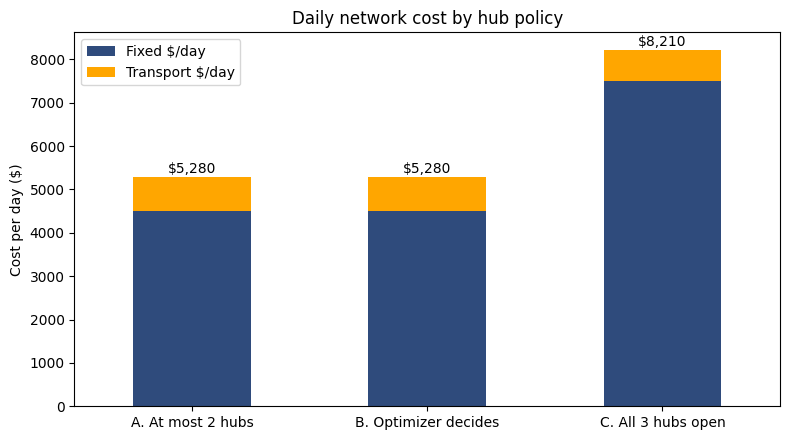

In [5]:
ax = summary[["Fixed $/day", "Transport $/day"]].astype(float).plot(
    kind="bar", stacked=True, figsize=(8, 4.5), color=["#2f4b7c", "#ffa600"])
ax.set_ylabel("Cost per day ($)")
ax.set_title("Daily network cost by hub policy")
ax.tick_params(axis="x", rotation=0)
for k, total in enumerate(summary["Total $/day"].astype(float)):
    ax.text(k, total + 100, f"${total:,.0f}", ha="center")
plt.tight_layout()
plt.savefig("images/hub_policy_costs.png", dpi=150)
plt.show()

## 4. Sensitivity: when would a third hub pay off?

In [6]:
rows = []
for rate in [2, 4, 6, 8, 10, 15, 20, 25, 30]:
    r = solve_hub_model(rate=rate)
    rows.append({"$/km/order": rate, "Open hubs": ", ".join(r["open_hubs"]), "Total $/day": round(r["total_cost"])})
sens = pd.DataFrame(rows)
print(sens.to_string(index=False))

 $/km/order      Open hubs  Total $/day
          2 North, Central         5280
          4 North, Central         6060
          6 North, Central         6840
          8 North, Central         7620
         10 North, Central         8400
         15 North, Central        10350
         20 North, Central        12300
         25 North, Central        14250
         30 North, Central        16200


## 5. Findings

- **Open two hubs (North and Central) and close South.** The two-hub network serves all 85 orders per day for the lowest cost, and the optimizer reaches the same answer even when it is free to open all three.
- **Fixed cost, not distance, drives the decision.** Forcing the third hub open saves only $70/day in transport but adds $3,000/day of fixed cost, so total cost rises from **$5,280 to $8,210 per day (+55%)**.
- **Central runs at 100% capacity.** It is the binding constraint: any growth in University, Suburbs, or Waterfront demand would push volume to North or force a third hub, so Central capacity is the first thing to watch.
- **The answer is stable.** Two hubs stay optimal even when the transport rate rises 15x (from $2 to $30 per km per order), which makes the two-hub plan a low-regret decision.

**Skills shown:** facility-location modelling, mixed-integer programming, Gurobi/Python, scenario and sensitivity analysis, translating a model into a network recommendation.